# Proyecto: Predicción del precio mensual de la gasolina

**Objetivo:** entrenar un modelo de regresión lineal múltiple para estimar el precio de la gasolina en USD/galón usando variables económicas, energéticas y geopolíticas.

El flujo del tablero es: **Datos → Limpieza → Modelado → Evaluación → Despliegue → Aplicación**. Se emplean `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `joblib` y `Streamlit`.

Se usa una partición didáctica del 70 % para entrenamiento y 30 % para prueba. Para un pronóstico temporal de producción conviene validar también respetando estrictamente el orden de las fechas.

> La calidad de la predicción depende de la calidad y representatividad del dataset. La columna `Fecha` sirve para ordenar los registros; no se utiliza como predictor numérico directo.

## 1. Importar librerías

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


## 2. Cargar el dataset

In [2]:
from pathlib import Path

# Busca el CSV junto al notebook o en la carpeta actual
nombre_csv = 'dataset_precio_gasolina (1) (3).csv'
rutas_posibles = [Path(nombre_csv), Path.cwd() / nombre_csv]
ruta = next((p for p in rutas_posibles if p.exists()), None)
if ruta is None:
    raise FileNotFoundError(
        f"No se encontro '{nombre_csv}'. Guarda el CSV en la misma carpeta del notebook "
        "o cambia la variable nombre_csv por la ruta correcta."
    )
df = pd.read_csv(ruta)
print('Archivo cargado:', ruta.resolve())
display(df.head())

Archivo cargado: C:\Users\willi\Desktop\Proyecto_Gasolina_Completo\dataset_precio_gasolina (1) (3).csv


,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
0,2018-01-01,8.17,73.94,3683.88,9673.0,27.45,3.84,3.54,1,18
1,2018-02-01,8.51,62.51,4404.09,9819.0,28.53,2.75,5.57,0,22
2,2018-03-01,8.17,76.66,2521.11,9254.0,28.03,3.25,2.28,0,22
3,2018-04-01,9.09,92.41,4069.86,9230.0,29.16,2.91,3.30,0,22
4,2018-05-01,8.10,60.79,3739.17,9746.0,33.63,2.79,3.88,0,18


## 3. Inspección inicial de los datos

In [3]:
print('Filas y columnas:', df.shape)
print('\nTipos de datos:')
print(df.dtypes)
print('\nValores nulos por columna:')
print(df.isnull().sum())
print('\nFilas duplicadas:', df.duplicated().sum())
display(df.describe(include='all'))


Filas y columnas: (72, 10)

Tipos de datos:
Fecha                                    str
Precio_Gasolina_USD_Galon            float64
Precio_Petroleo_USD_Barril           float64
Tipo_Cambio_USD_COP                  float64
Demanda_miles_barriles_dia           float64
Produccion_OPEP_millones_dia         float64
Inflacion_Porcentaje                 float64
PIB_Porcentaje                       float64
Eventos_Geopoliticos                   int64
Impuestos_Combustibles_Porcentaje      int64
dtype: object

Valores nulos por columna:
Fecha                                0
Precio_Gasolina_USD_Galon            0
Precio_Petroleo_USD_Barril           0
Tipo_Cambio_USD_COP                  0
Demanda_miles_barriles_dia           0
Produccion_OPEP_millones_dia         0
Inflacion_Porcentaje                 0
PIB_Porcentaje                       0
Eventos_Geopoliticos                 0
Impuestos_Combustibles_Porcentaje    0
dtype: int64

Filas duplicadas: 0


,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
count,72,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000
unique,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2018-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,8.104444,63.117778,3674.238611,9652.069444,28.897778,3.563333,2.779167,0.138889,22.180556
std,NaN,0.790899,16.383220,444.171734,270.140304,2.134165,0.883983,2.120914,0.348257,3.229819
min,NaN,6.560000,29.730000,2521.110000,9176.000000,25.000000,1.760000,-1.750000,0.000000,18.000000
25%,NaN,7.487500,53.247500,3429.897500,9407.500000,27.517500,2.827500,1.225000,0.000000,21.000000
50%,NaN,8.080000,62.085000,3686.225000,9682.500000,28.825000,3.510000,2.735000,0.000000,22.000000
75%,NaN,8.730000,74.147500,3889.645000,9788.000000,30.330000,4.250000,4.405000,0.000000,25.000000


## 4. Limpieza de datos

In [4]:
# Trabajamos sobre una copia para conservar el dataset original
df = df.copy()

# Limpiar fechas, duplicados, tipos de datos y variable objetivo
df['Fecha'] = pd.to_datetime(df['Fecha'], errors='coerce')
df = df.drop_duplicates()
df = df.dropna(subset=['Fecha'])
df = df.sort_values('Fecha').reset_index(drop=True)

for columna in df.columns:
    if columna != 'Fecha':
        df[columna] = pd.to_numeric(df[columna], errors='coerce')

objetivo = 'Precio_Gasolina_USD_Galon'
# No se puede entrenar con filas sin precio objetivo o con precio no positivo
df = df[df[objetivo].notna() & (df[objetivo] > 0)].copy()

print('Tamaño después de limpieza:', df.shape)
print('Valores faltantes por columna (los faltantes de X se imputarán con mediana):')
print(df.isnull().sum())
display(df.head())

Tamaño después de limpieza: (72, 10)
Valores faltantes por columna (los faltantes de X se imputarán con mediana):
Fecha                                0
Precio_Gasolina_USD_Galon            0
Precio_Petroleo_USD_Barril           0
Tipo_Cambio_USD_COP                  0
Demanda_miles_barriles_dia           0
Produccion_OPEP_millones_dia         0
Inflacion_Porcentaje                 0
PIB_Porcentaje                       0
Eventos_Geopoliticos                 0
Impuestos_Combustibles_Porcentaje    0
dtype: int64


,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
0,2018-01-01,8.17,73.94,3683.88,9673.0,27.45,3.84,3.54,1,18
1,2018-02-01,8.51,62.51,4404.09,9819.0,28.53,2.75,5.57,0,22
2,2018-03-01,8.17,76.66,2521.11,9254.0,28.03,3.25,2.28,0,22
3,2018-04-01,9.09,92.41,4069.86,9230.0,29.16,2.91,3.30,0,22
4,2018-05-01,8.10,60.79,3739.17,9746.0,33.63,2.79,3.88,0,18


## 5. Definir variables independientes (X) y dependiente (y)

La variable dependiente `y` es el precio de gasolina. Las demás variables numéricas son las características `X`. Los valores faltantes de las características se imputarán con la mediana dentro del pipeline, evitando calcular la mediana con los datos de prueba.


In [5]:
objetivo = 'Precio_Gasolina_USD_Galon'
columnas_no_predictoras = ['Fecha', objetivo]
caracteristicas = [c for c in df.select_dtypes(include=np.number).columns if c not in columnas_no_predictoras]
X = df[caracteristicas].copy()
y = df[objetivo].copy()

print('Variables independientes (X):')
print(caracteristicas)
print('Variable dependiente (y):', objetivo)

Variables independientes (X):
['Precio_Petroleo_USD_Barril', 'Tipo_Cambio_USD_COP', 'Demanda_miles_barriles_dia', 'Produccion_OPEP_millones_dia', 'Inflacion_Porcentaje', 'PIB_Porcentaje', 'Eventos_Geopoliticos', 'Impuestos_Combustibles_Porcentaje']
Variable dependiente (y): Precio_Gasolina_USD_Galon


## 6. Análisis estadístico y correlación

,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje,Precio_Gasolina_USD_Galon
Precio_Petroleo_USD_Barril,1.00,-0.01,0.24,-0.03,-0.24,-0.12,0.05,-0.02,0.78
Tipo_Cambio_USD_COP,-0.01,1.00,0.06,0.15,0.11,0.02,0.14,-0.12,0.11
Demanda_miles_barriles_dia,0.24,0.06,1.00,0.19,0.08,-0.02,-0.00,0.20,0.35
Produccion_OPEP_millones_dia,-0.03,0.15,0.19,1.00,-0.02,0.12,-0.03,-0.14,0.07
Inflacion_Porcentaje,-0.24,0.11,0.08,-0.02,1.00,-0.02,0.18,0.05,-0.28
PIB_Porcentaje,-0.12,0.02,-0.02,0.12,-0.02,1.00,0.01,-0.11,0.26
Eventos_Geopoliticos,0.05,0.14,-0.00,-0.03,0.18,0.01,1.00,-0.05,0.23
Impuestos_Combustibles_Porcentaje,-0.02,-0.12,0.20,-0.14,0.05,-0.11,-0.05,1.00,0.23
Precio_Gasolina_USD_Galon,0.78,0.11,0.35,0.07,-0.28,0.26,0.23,0.23,1.00


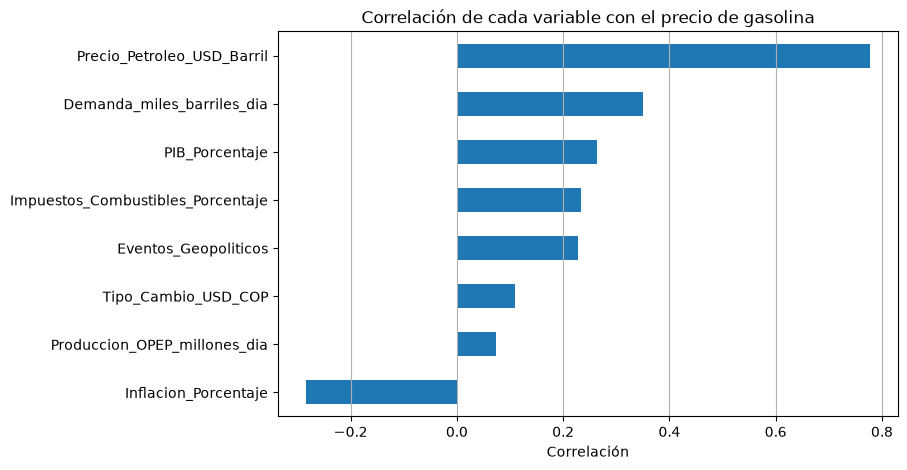

In [6]:
display(df[caracteristicas + [objetivo]].corr().round(2))

correlaciones = df[caracteristicas + [objetivo]].corr()[objetivo].drop(objetivo).sort_values()
correlaciones.plot(kind='barh', figsize=(8, 5), title='Correlación de cada variable con el precio de gasolina')
plt.xlabel('Correlación')
plt.grid(axis='x')
plt.show()


## 7. Revisar posibles valores atípicos

In [7]:
# Detección preliminar de posibles valores atípicos mediante rango intercuartílico (IQR).
# La marca es una señal para revisar, no implica que un dato sea erróneo.
for columna in caracteristicas + [objetivo]:
    valores = df[columna].dropna()
    if valores.empty:
        print(f'{columna}: sin valores para revisar')
        continue
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    cantidad = ((valores < limite_inferior) | (valores > limite_superior)).sum()
    print(f'{columna}: {cantidad} posibles valores atípicos')

print('Nota: las variables binarias/discretas, como Eventos_Geopoliticos, no se recortarán por IQR.')

Precio_Petroleo_USD_Barril: 0 posibles valores atípicos
Tipo_Cambio_USD_COP: 3 posibles valores atípicos
Demanda_miles_barriles_dia: 2 posibles valores atípicos
Produccion_OPEP_millones_dia: 0 posibles valores atípicos
Inflacion_Porcentaje: 0 posibles valores atípicos
PIB_Porcentaje: 0 posibles valores atípicos
Eventos_Geopoliticos: 10 posibles valores atípicos
Impuestos_Combustibles_Porcentaje: 0 posibles valores atípicos
Precio_Gasolina_USD_Galon: 0 posibles valores atípicos
Nota: las variables binarias/discretas, como Eventos_Geopoliticos, no se recortarán por IQR.


## 8. Dividir datos en entrenamiento y prueba

In [8]:
# Separación 70/30 como en el tablero: 70% entrenamiento y 30% prueba.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# TRATAMIENTO de valores atípicos usando límites calculados solo con entrenamiento.
# Solo se recortan variables continuas (>10 valores distintos); así no tratamos una variable
# binaria como Eventos_Geopoliticos como si sus ceros fueran valores atípicos.
limites_atipicos = {}
for columna in caracteristicas:
    if X_train[columna].nunique(dropna=True) > 10 and X_train[columna].notna().any():
        q1 = X_train[columna].quantile(0.25)
        q3 = X_train[columna].quantile(0.75)
        iqr = q3 - q1
        inferior = float(q1 - 1.5 * iqr)
        superior = float(q3 + 1.5 * iqr)
        limites_atipicos[columna] = (inferior, superior)
        X_train.loc[:, columna] = X_train[columna].clip(inferior, superior)
        X_test.loc[:, columna] = X_test[columna].clip(inferior, superior)

# Si hubiera precios objetivo atípicos en entrenamiento, se excluyen solo de ese conjunto;
# el conjunto de prueba se conserva sin modificar para evaluar el rendimiento.
q1_y = y_train.quantile(0.25)
q3_y = y_train.quantile(0.75)
iqr_y = q3_y - q1_y
limite_y_inferior = q1_y - 1.5 * iqr_y
limite_y_superior = q3_y + 1.5 * iqr_y
mascara_y = y_train.between(limite_y_inferior, limite_y_superior)
filas_objetivo_atipicas = int((~mascara_y).sum())
X_train = X_train.loc[mascara_y].copy()
y_train = y_train.loc[mascara_y].copy()

print('Entrenamiento después del tratamiento de atípicos:', X_train.shape[0])
print('Datos de prueba:', X_test.shape[0])
print('Filas de entrenamiento excluidas por precio objetivo atípico:', filas_objetivo_atipicas)
print('Límites IQR aplicados a las variables continuas:', limites_atipicos)

Entrenamiento después del tratamiento de atípicos: 49
Datos de prueba: 22
Filas de entrenamiento excluidas por precio objetivo atípico: 1
Límites IQR aplicados a las variables continuas: {'Precio_Petroleo_USD_Barril': (28.3225, 97.72250000000001), 'Tipo_Cambio_USD_COP': (2781.3512500000006, 4613.601249999999), 'Demanda_miles_barriles_dia': (8770.25, 10386.25), 'Produccion_OPEP_millones_dia': (23.413749999999993, 34.44375000000001), 'Inflacion_Porcentaje': (0.6812499999999995, 6.39125), 'PIB_Porcentaje': (-3.5187500000000007, 8.27125)}


## 9. Crear y entrenar el modelo

In [9]:
# Pipeline de procesamiento y modelo: imputar faltantes, normalizar variables y entrenar regresión lineal.
# El imputador y el normalizador se ajustan solo con los datos de entrenamiento.
modelo = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('normalizador', StandardScaler()),
    ('regresion', LinearRegression())
])
modelo.fit(X_train, y_train)
print('Modelo de regresión lineal múltiple entrenado correctamente.')

Modelo de regresión lineal múltiple entrenado correctamente.


## 10. Intercepto y coeficientes

In [10]:
regresion = modelo.named_steps['regresion']
print('Intercepto b0 =', regresion.intercept_)

coeficientes = pd.DataFrame({
    'Variable': caracteristicas,
    'Coeficiente': regresion.coef_
})
display(coeficientes)
print('Nota: los coeficientes corresponden a las variables normalizadas por StandardScaler.')


Intercepto b0 = 8.017551020408163


,Variable,Coeficiente
0,Precio_Petroleo_USD_Barril,0.615623
1,Tipo_Cambio_USD_COP,0.078657
2,Demanda_miles_barriles_dia,0.066320
3,Produccion_OPEP_millones_dia,0.012093
4,Inflacion_Porcentaje,-0.140205
5,PIB_Porcentaje,0.273306
6,Eventos_Geopoliticos,0.162149
7,Impuestos_Combustibles_Porcentaje,0.242470


Nota: los coeficientes corresponden a las variables normalizadas por StandardScaler.


## 11. Evaluar el modelo: RMSE, MAE y R²

In [11]:
y_pred = modelo.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MSE:  {mse:.4f} (USD/galón)^2')
print(f'RMSE: {rmse:.4f} USD/galón')
print(f'MAE:  {mae:.4f} USD/galón')
print(f'R²:   {r2:.4f}')

MSE:  0.0915 (USD/galón)^2
RMSE: 0.3024 USD/galón
MAE:  0.2475 USD/galón
R²:   0.8519


## 12. Comparar precios reales y predichos

,Precio real,Precio predicho
0,8.10,7.975877
1,6.97,7.155348
2,8.25,8.123540
3,8.17,8.702247
4,7.41,7.351990
5,9.35,9.039136
6,7.61,7.456283
7,8.82,9.205038
8,8.71,8.830777
9,8.25,8.467233


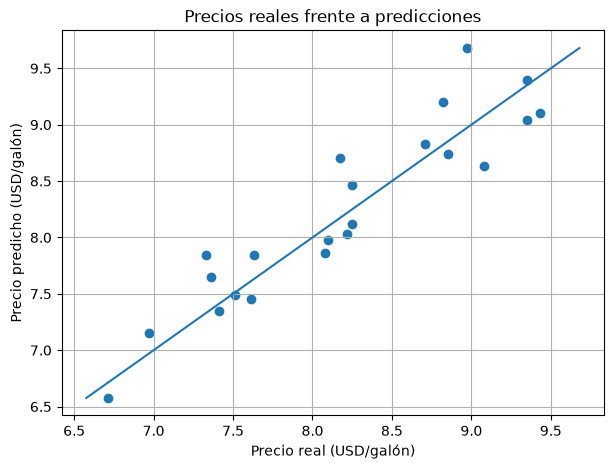

In [12]:
comparacion = pd.DataFrame({'Precio real': y_test.values, 'Precio predicho': y_pred})
display(comparacion.head(10))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)
minimo = min(y_test.min(), y_pred.min())
maximo = max(y_test.max(), y_pred.max())
plt.plot([minimo, maximo], [minimo, maximo])
plt.xlabel('Precio real (USD/galón)')
plt.ylabel('Precio predicho (USD/galón)')
plt.title('Precios reales frente a predicciones')
plt.grid(True)
plt.show()


## 13. Predicción nueva e intervalo aproximado del 95%

In [13]:
# Ejemplo: usar la primera fila del conjunto de prueba como entrada.
entrada = X_test.iloc[[0]].copy()
prediccion = float(modelo.predict(entrada)[0])

# Intervalo empírico de predicción al 95% usando los errores absolutos del conjunto de prueba
# como calibración (aproximación conformal). Con pocos registros puede ser amplio.
errores_calibracion = np.abs(y_test.to_numpy() - y_pred)
n_calibracion = len(errores_calibracion)
if n_calibracion == 0:
    raise ValueError('No hay registros de prueba para calcular el intervalo del 95%.')
rango = min(n_calibracion, int(np.ceil((n_calibracion + 1) * 0.95)))
semiancho = float(np.sort(errores_calibracion)[rango - 1])

print(f'Precio estimado: {prediccion:.2f} USD/galón')
print(f'Intervalo empírico aproximado del 95%: [{prediccion-semiancho:.2f}, {prediccion+semiancho:.2f}] USD/galón')
print('Nota: es un intervalo predictivo empírico calibrado con el conjunto de prueba; no es un intervalo para la media.')
display(entrada)

Precio estimado: 7.98 USD/galón
Intervalo empírico aproximado del 95%: [7.27, 8.69] USD/galón
Nota: es un intervalo predictivo empírico calibrado con el conjunto de prueba; no es un intervalo para la media.


,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
4,60.79,3739.17,9746.0,33.63,2.79,3.88,0,18


## 14. Guardar resultados

In [14]:
# Guardar comparación de evaluación y exportar el modelo para el aplicativo.
comparacion.to_csv('resultados_prediccion_gasolina.csv', index=False)

paquete_modelo = {
    'modelo': modelo,
    'caracteristicas': caracteristicas,
    'limites_atipicos': limites_atipicos,
    'metricas': {'MSE': float(mse), 'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r2)},
    'margen_intervalo_95': float(semiancho),
    'objetivo': objetivo
}
joblib.dump(paquete_modelo, 'modelo_gasolina.pkl')
print('Guardado: resultados_prediccion_gasolina.csv')
print('Modelo exportado para Streamlit: modelo_gasolina.pkl')

Guardado: resultados_prediccion_gasolina.csv
Modelo exportado para Streamlit: modelo_gasolina.pkl


## 15. Conclusión

El flujo del proyecto sigue las etapas del tablero: datos, limpieza, definición de X e y, entrenamiento 70/30, modelado con regresión lineal, evaluación con **MSE, RMSE, MAE y R²**, exportación del modelo a `modelo_gasolina.pkl` y despliegue con Streamlit.

Un MAE y RMSE más bajos indican errores menores. Un R² más cercano a 1 indica que el modelo explica una mayor proporción de la variación observada en el conjunto evaluado. Los resultados dependen del dataset y no garantizan el comportamiento futuro del precio real de mercado.

El notebook genera `modelo_gasolina.pkl`, que es el archivo cargado por `app_gasolina.py` para ofrecer predicciones sin volver a entrenar el modelo cada vez que se abre la aplicación.